In [32]:
import pandas as pd

df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report

)

In [34]:
TRAIN, TEST = train_test_split(df, train_size=0.8, random_state=42)

X_train = TRAIN.drop(columns="Layoff_Risk")
y_train = TRAIN["Layoff_Risk"]

X_test = TEST.drop(columns="Layoff_Risk")
y_test = TEST["Layoff_Risk"]

In [35]:
# Column names come from X_train so the target (Layoff_Risk) is excluded
cat_cols = X_train.select_dtypes(include="str").columns
num_cols = X_train.select_dtypes(include="number").columns

# One-hot encode text columns, scale numeric columns
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])

# Encoder and scaler are fit on training data only
model.fit(X_train, y_train)
model.score(X_test, y_test)

0.94125

In [36]:
# Baseline: always predict the most common class in the training data
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline.score(X_test, y_test)

0.34375

In [37]:
# Coefficients: one column per class, one row per (encoded) feature
# Numeric features are standardized, so their coefficients are per 1 standard deviation
labels = ["Low", "Medium", "High"]

coefs = pd.DataFrame(
    model["clf"].coef_.T,
    index=model["prep"].get_feature_names_out(),
    columns=model["clf"].classes_,
)[labels]

# Sort by size of effect on "High" risk
coefs = coefs.reindex(coefs["High"].abs().sort_values(ascending=False).index)
pd.set_option("display.max_rows", None)
coefs.round(3)

,Low,Medium,High
cat__Job_Level_Senior,7.331,0.526,-7.857
cat__Job_Level_Entry,-5.962,0.524,5.439
cat__Education_Level_PhD,4.447,0.278,-4.724
cat__Education_Level_High School,-5.112,0.503,4.609
num__Routine_Task_Percentage,-4.552,0.075,4.477
cat__Industry_Education,4.280,0.149,-4.428
num__Tasks_Automated_Percentage,-4.221,0.007,4.215
cat__Industry_Healthcare,3.591,0.192,-3.783
cat__Industry_Manufacturing,-3.663,0.242,3.421
num__Creativity_Requirement,3.089,0.046,-3.135


In [38]:
# Confusion matrix: rows = actual class, columns = predicted class
labels = ["Low", "Medium", "High"]
cm = confusion_matrix(y_test, model.predict(X_test), labels=labels)

pd.DataFrame(cm,
             index=[f"actual {l}" for l in labels],
             columns=[f"pred {l}" for l in labels])

,pred Low,pred Medium,pred High
actual Low,1243,53,0
actual Medium,56,1212,61
actual High,0,65,1310


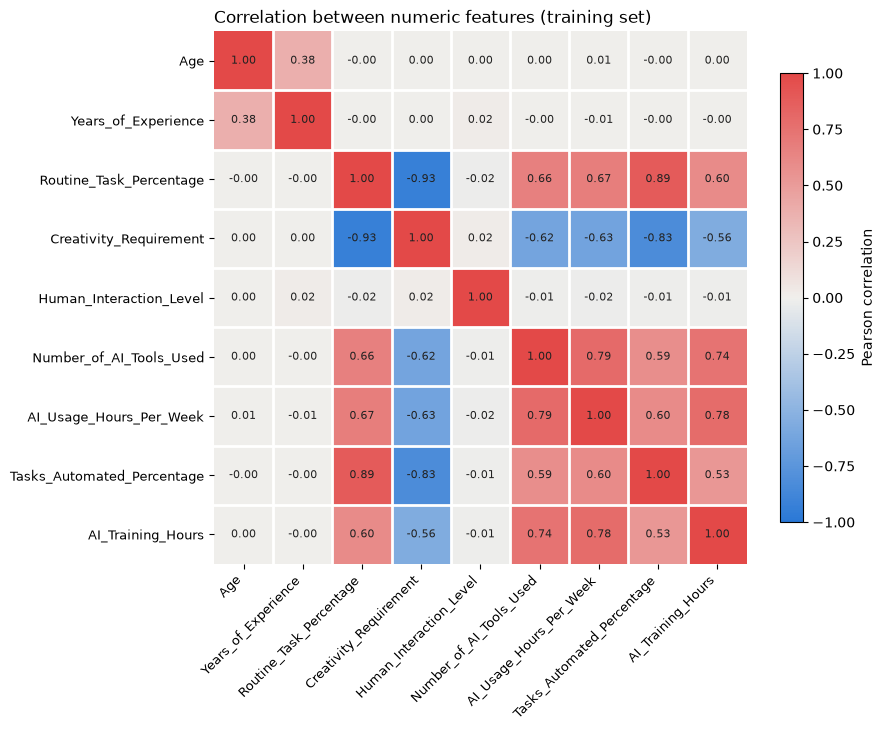

,feature_1,feature_2,correlation
0,Routine_Task_Percentage,Creativity_Requirement,-0.93
1,Routine_Task_Percentage,Tasks_Automated_Percentage,0.89
2,Creativity_Requirement,Tasks_Automated_Percentage,-0.83
3,AI_Adoption_Level_Low,Routine_Task_Percentage,-0.79
4,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,0.79
5,AI_Usage_Hours_Per_Week,AI_Training_Hours,0.78
6,AI_Adoption_Level_High,AI_Training_Hours,0.75
7,Number_of_AI_Tools_Used,AI_Training_Hours,0.74
8,AI_Adoption_Level_Low,AI_Usage_Hours_Per_Week,-0.74
9,AI_Adoption_Level_Low,Creativity_Requirement,0.74


,corr_with_risk,coef_High
Routine_Task_Percentage,0.780,4.477
Creativity_Requirement,-0.752,-3.135
Tasks_Automated_Percentage,0.747,4.215
AI_Adoption_Level_Low,-0.619,-0.610
AI_Usage_Hours_Per_Week,0.506,-0.050
Number_of_AI_Tools_Used,0.500,0.005
AI_Adoption_Level_Medium,0.490,-0.640
AI_Training_Hours,0.432,-0.947
AI_Adoption_Level_High,0.268,-0.609
Job_Level_Senior,-0.249,-7.857


In [39]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

# Encode the training features exactly as the model sees them
prep = model["prep"]
X_t = prep.transform(X_train)
if hasattr(X_t, "toarray"):   # one-hot output can be a sparse matrix
    X_t = X_t.toarray()
X_enc = pd.DataFrame(X_t, columns=prep.get_feature_names_out())
X_enc.columns = X_enc.columns.str.replace(r"^(cat|num)__", "", regex=True)
num_feats = list(num_cols)

# 1. Correlation heatmap of the numeric features
corr_num = X_enc[num_feats].corr()
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_num, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_feats)), num_feats, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(num_feats)), num_feats, fontsize=9)
for i in range(len(num_feats)):
    for j in range(len(num_feats)):
        ax.text(j, i, f"{corr_num.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=8, color="#222222")
ax.set_xticks([x - 0.5 for x in range(1, len(num_feats))], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, len(num_feats))], minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between numeric features (training set)", loc="left")
plt.tight_layout()
plt.show()

# 2. Most correlated feature pairs across ALL encoded features
#    (skips pairs from the same one-hot column, which are always negatively correlated)
def source_col(f):
    return next((c for c in cat_cols if f.startswith(c + "_")), f)

corr_all = X_enc.corr()
upper = corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1)).stack()
upper = upper[[source_col(a) != source_col(b) for a, b in upper.index]]
top_pairs = (upper.reindex(upper.abs().sort_values(ascending=False).index)
             .head(15).round(2).rename("correlation")
             .rename_axis(["feature_1", "feature_2"]).reset_index())
display(top_pairs)

# 3. Each feature's own correlation with risk (Low=0, Medium=1, High=2)
#    next to its model coefficient for "High"
risk_num = y_train.map({"Low": 0, "Medium": 1, "High": 2}).to_numpy()
importance = pd.DataFrame({
    "corr_with_risk": X_enc.apply(lambda col: np.corrcoef(col, risk_num)[0, 1]),
    "coef_High": model["clf"].coef_[list(model["clf"].classes_).index("High")],
})
importance = importance.reindex(importance["corr_with_risk"].abs()
                                .sort_values(ascending=False).index)
display(importance.round(3).head(20))